In [ ]:
from google.colab import drive
drive.mount("/content/drive")

import os
import json
import joblib
import pandas as pd
import numpy as np

print("Drive mounted and basic libraries loaded.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Drive mounted and basic libraries loaded.


In [ ]:
BASE_PATH = "/content/drive/MyDrive/AI_Research_Paper_1"

MODEL_ARTIFACT_PATH = os.path.join(
    BASE_PATH,
    "model_artifacts"
)

RESULTS_PATH = os.path.join(
    BASE_PATH,
    "results"
)

print("BASE_PATH exists:",
      os.path.exists(BASE_PATH))

print("MODEL_ARTIFACT_PATH exists:",
      os.path.exists(MODEL_ARTIFACT_PATH))

print("\nSaved model artifacts:")

for file in sorted(
    os.listdir(MODEL_ARTIFACT_PATH)
):
    print(file)

BASE_PATH exists: True
MODEL_ARTIFACT_PATH exists: True

Saved model artifacts:
environment_versions.csv
model_metadata.json
xgb_leaky_10.joblib
xgb_leaky_20.joblib
xgb_leaky_30.joblib
xgb_leaky_40.joblib
xgb_lf_10.joblib
xgb_lf_20.joblib
xgb_lf_30.joblib
xgb_lf_40.joblib


In [ ]:
saved_versions = pd.read_csv(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "environment_versions.csv"
    )
)

print("=== SAVED ENVIRONMENT ===")
print(
    saved_versions.to_string(
        index=False
    )
)

=== SAVED ENVIRONMENT ===
     Package Version
      Python 3.12.13
      pandas   2.2.2
       numpy   2.0.2
scikit-learn   1.6.1
     xgboost   3.3.0


In [ ]:
import sys
import sklearn
import xgboost as xgb

current_versions = pd.DataFrame({
    "Package": [
        "Python",
        "pandas",
        "numpy",
        "scikit-learn",
        "xgboost"
    ],
    "Current_Version": [
        sys.version.split()[0],
        pd.__version__,
        np.__version__,
        sklearn.__version__,
        xgb.__version__
    ]
})

print("=== CURRENT ENVIRONMENT ===")
print(
    current_versions.to_string(
        index=False
    )
)

=== CURRENT ENVIRONMENT ===
     Package Current_Version
      Python         3.12.13
      pandas           2.2.2
       numpy           2.0.2
scikit-learn           1.6.1
     xgboost           3.3.0


In [ ]:
with open(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "model_metadata.json"
    ),
    "r"
) as f:

    metadata = json.load(f)

primary_features = metadata[
    "primary_features"
]

numeric_features = metadata[
    "numeric_features"
]

categorical_features = metadata[
    "categorical_features"
]

target_mapping = metadata[
    "target_mapping"
]

class_order = metadata[
    "class_order"
]

cutoffs = metadata[
    "cutoffs"
]

print("Primary predictors:",
      len(primary_features))

print("Numeric predictors:",
      len(numeric_features))

print("Categorical predictors:",
      len(categorical_features))

print("Class order:",
      class_order)

print("Cutoffs:",
      cutoffs)

print("\nTarget mapping:")
print(target_mapping)

Primary predictors: 25
Numeric predictors: 20
Categorical predictors: 5
Class order: ['Distinction', 'Pass', 'Fail', 'Withdrawn']
Cutoffs: [10, 20, 30, 40]

Target mapping:
{'Distinction': 0, 'Pass': 1, 'Fail': 2, 'Withdrawn': 3}


In [ ]:
xgb_lf_10 = joblib.load(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "xgb_lf_10.joblib"
    )
)

xgb_leaky_10 = joblib.load(
    os.path.join(
        MODEL_ARTIFACT_PATH,
        "xgb_leaky_10.joblib"
    )
)

print("10% models loaded successfully.")

print(
    "\nLeakage-free pipeline steps:",
    xgb_lf_10.named_steps.keys()
)

print(
    "Leaky pipeline steps:",
    xgb_leaky_10.named_steps.keys()
)

10% models loaded successfully.

Leakage-free pipeline steps: dict_keys(['preprocessor', 'model'])
Leaky pipeline steps: dict_keys(['preprocessor', 'model'])


In [ ]:
required_files = [
    "leakage_free_10.csv",
    "leaky_10.csv",
    "master_student_split.csv"
]

found_files = {}

for root, dirs, files in os.walk(BASE_PATH):
    for filename in required_files:
        if filename in files:
            found_files[filename] = os.path.join(
                root,
                filename
            )

print("=== REQUIRED FILE LOCATIONS ===")

for filename in required_files:
    print(
        filename,
        "->",
        found_files.get(filename, "NOT FOUND")
    )

=== REQUIRED FILE LOCATIONS ===
leakage_free_10.csv -> /content/drive/MyDrive/AI_Research_Paper_1/processed/model_datasets/leakage_free_10.csv
leaky_10.csv -> /content/drive/MyDrive/AI_Research_Paper_1/processed/leaky_datasets/leaky_10.csv
master_student_split.csv -> /content/drive/MyDrive/AI_Research_Paper_1/processed/splits/master_student_split.csv


In [ ]:
lf_raw_10 = pd.read_csv(
    found_files["leakage_free_10.csv"]
)

leaky_raw_10 = pd.read_csv(
    found_files["leaky_10.csv"]
)

master_students = pd.read_csv(
    found_files["master_student_split.csv"]
)

print("Leakage-free rows:", len(lf_raw_10))
print("Leaky rows:", len(leaky_raw_10))
print("Master split rows:", len(master_students))

print("\nLF columns:", len(lf_raw_10.columns))
print("Leaky columns:", len(leaky_raw_10.columns))

Leakage-free rows: 27652
Leaky rows: 27652
Master split rows: 24954

LF columns: 31
Leaky columns: 31


In [ ]:
def canonicalize_for_shap(df, p, condition):

    data = df.copy()

    if condition == "leakage_free":

        rename_map = {
            f"vle_clicks_{p}": "vle_clicks",
            f"vle_active_days_{p}": "vle_active_days",
            f"vle_unique_sites_{p}": "vle_unique_sites",

            f"content_clicks_{p}": "content_clicks",
            f"forum_clicks_{p}": "forum_clicks",
            f"navigation_clicks_{p}": "navigation_clicks",

            f"assessments_submitted_{p}":
                "assessments_submitted",

            f"tma_submitted_{p}":
                "tma_submitted",

            f"cma_submitted_{p}":
                "cma_submitted",

            f"late_submissions_{p}":
                "late_submissions",

            f"mean_submission_delay_{p}":
                "mean_submission_delay",

            f"scored_assessments_{p}":
                "scored_assessments",

            f"mean_score_due_{p}":
                "mean_score",

            f"has_score_due_{p}":
                "has_score"
        }

    elif condition == "leaky":

        rename_map = {
            "vle_clicks_full": "vle_clicks",
            "vle_active_days_full":
                "vle_active_days",
            "vle_unique_sites_full":
                "vle_unique_sites",

            "content_clicks_full":
                "content_clicks",
            "forum_clicks_full":
                "forum_clicks",
            "navigation_clicks_full":
                "navigation_clicks",

            "assessments_submitted_full":
                "assessments_submitted",

            "tma_submitted_full":
                "tma_submitted",

            "cma_submitted_full":
                "cma_submitted",

            "late_submissions_full":
                "late_submissions",

            "mean_submission_delay_full":
                "mean_submission_delay",

            "scored_assessments_full":
                "scored_assessments",

            "mean_score_full":
                "mean_score",

            "has_score_full":
                "has_score"
        }

    return data.rename(
        columns=rename_map
    )


lf10 = canonicalize_for_shap(
    lf_raw_10,
    10,
    "leakage_free"
)

leaky10 = canonicalize_for_shap(
    leaky_raw_10,
    10,
    "leaky"
)

print(
    "Same canonical schema:",
    set(lf10.columns)
    ==
    set(leaky10.columns)
)

Same canonical schema: True


In [ ]:
keys = [
    "code_module",
    "code_presentation",
    "id_student"
]

lf10 = lf10.merge(
    master_students,
    on="id_student",
    how="left",
    validate="many_to_one"
)

leaky10 = leaky10.merge(
    master_students,
    on="id_student",
    how="left",
    validate="many_to_one"
)

lf10 = (
    lf10
    .sort_values(keys)
    .reset_index(drop=True)
)

leaky10 = (
    leaky10
    .sort_values(keys)
    .reset_index(drop=True)
)

print(
    "Missing LF split assignments:",
    lf10["split"].isna().sum()
)

print(
    "Missing leaky split assignments:",
    leaky10["split"].isna().sum()
)

Missing LF split assignments: 0
Missing leaky split assignments: 0


In [ ]:
test_lf_10 = (
    lf10[
        lf10["split"] == "test"
    ]
    .reset_index(drop=True)
)

test_leaky_10 = (
    leaky10[
        leaky10["split"] == "test"
    ]
    .reset_index(drop=True)
)

X_test_lf_10 = test_lf_10[
    primary_features
].copy()

X_test_leaky_10 = test_leaky_10[
    primary_features
].copy()

print("LF test rows:", len(X_test_lf_10))
print("Leaky test rows:", len(X_test_leaky_10))

print(
    "Same registration records:",
    test_lf_10[keys].equals(
        test_leaky_10[keys]
    )
)

print(
    "Same true outcomes:",
    test_lf_10["final_result"].equals(
        test_leaky_10["final_result"]
    )
)

LF test rows: 5514
Leaky test rows: 5514
Same registration records: True
Same true outcomes: True


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score
)

y_test_10 = (
    test_lf_10["final_result"]
    .map(target_mapping)
    .astype(int)
)

pred_lf_10 = xgb_lf_10.predict(
    X_test_lf_10
)

pred_leaky_10 = xgb_leaky_10.predict(
    X_test_leaky_10
)

print("=== RELOADED MODEL CHECK ===")

print("\nLeakage-Free")
print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test_10,
            pred_lf_10
        ),
        4
    )
)
print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test_10,
            pred_lf_10
        ),
        4
    )
)
print(
    "Macro-F1:",
    round(
        f1_score(
            y_test_10,
            pred_lf_10,
            average="macro"
        ),
        4
    )
)

print("\nLeaky")
print(
    "Accuracy:",
    round(
        accuracy_score(
            y_test_10,
            pred_leaky_10
        ),
        4
    )
)
print(
    "Balanced Accuracy:",
    round(
        balanced_accuracy_score(
            y_test_10,
            pred_leaky_10
        ),
        4
    )
)
print(
    "Macro-F1:",
    round(
        f1_score(
            y_test_10,
            pred_leaky_10,
            average="macro"
        ),
        4
    )
)

=== RELOADED MODEL CHECK ===

Leakage-Free
Accuracy: 0.5359
Balanced Accuracy: 0.399
Macro-F1: 0.4088

Leaky
Accuracy: 0.7055
Balanced Accuracy: 0.6264
Macro-F1: 0.6425


In [ ]:
preprocessor_lf_10 = (
    xgb_lf_10
    .named_steps["preprocessor"]
)

preprocessor_leaky_10 = (
    xgb_leaky_10
    .named_steps["preprocessor"]
)

model_lf_10 = (
    xgb_lf_10
    .named_steps["model"]
)

model_leaky_10 = (
    xgb_leaky_10
    .named_steps["model"]
)


X_test_lf_transformed = (
    preprocessor_lf_10.transform(
        X_test_lf_10
    )
)

X_test_leaky_transformed = (
    preprocessor_leaky_10.transform(
        X_test_leaky_10
    )
)

print(
    "LF transformed shape:",
    X_test_lf_transformed.shape
)

print(
    "Leaky transformed shape:",
    X_test_leaky_transformed.shape
)

LF transformed shape: (5514, 50)
Leaky transformed shape: (5514, 50)


In [ ]:
feature_names_lf = (
    preprocessor_lf_10
    .get_feature_names_out()
)

feature_names_leaky = (
    preprocessor_leaky_10
    .get_feature_names_out()
)

print(
    "LF transformed features:",
    len(feature_names_lf)
)

print(
    "Leaky transformed features:",
    len(feature_names_leaky)
)

print(
    "\nSame transformed feature names:",
    np.array_equal(
        feature_names_lf,
        feature_names_leaky
    )
)

print("\nFirst 20 transformed features:")

for feature in feature_names_lf[:20]:
    print(feature)

LF transformed features: 50
Leaky transformed features: 50

Same transformed feature names: True

First 20 transformed features:
numeric__num_of_prev_attempts
numeric__studied_credits
numeric__date_registration
numeric__precourse_clicks
numeric__precourse_active_days
numeric__precourse_unique_sites
numeric__vle_clicks
numeric__vle_active_days
numeric__vle_unique_sites
numeric__content_clicks
numeric__forum_clicks
numeric__navigation_clicks
numeric__assessments_submitted
numeric__tma_submitted
numeric__cma_submitted
numeric__late_submissions
numeric__mean_submission_delay
numeric__scored_assessments
numeric__mean_score
numeric__has_score


In [ ]:
import shap

print(
    "SHAP version:",
    shap.__version__
)

print(
    "SHAP imported successfully."
)

SHAP version: 0.52.0
SHAP imported successfully.


In [ ]:
print("=== PRE-SHAP AUDIT ===")

print(
    "LF transformed shape:",
    X_test_lf_transformed.shape
)

print(
    "Leaky transformed shape:",
    X_test_leaky_transformed.shape
)

print(
    "Same transformed feature names:",
    np.array_equal(
        feature_names_lf,
        feature_names_leaky
    )
)

print(
    "Number of transformed features:",
    len(feature_names_lf)
)

print(
    "SHAP version:",
    shap.__version__
)

=== PRE-SHAP AUDIT ===
LF transformed shape: (5514, 50)
Leaky transformed shape: (5514, 50)
Same transformed feature names: True
Number of transformed features: 50
SHAP version: 0.52.0


In [ ]:
explainer_lf_10 = shap.TreeExplainer(
    model_lf_10
)

explainer_leaky_10 = shap.TreeExplainer(
    model_leaky_10
)

print("Both 10% TreeExplainers created successfully.")

Both 10% TreeExplainers created successfully.


In [ ]:
SHAP_PROBE_SIZE = 200

X_probe_lf = (
    X_test_lf_transformed[
        :SHAP_PROBE_SIZE
    ]
)

X_probe_leaky = (
    X_test_leaky_transformed[
        :SHAP_PROBE_SIZE
    ]
)

shap_probe_lf = (
    explainer_lf_10.shap_values(
        X_probe_lf
    )
)

shap_probe_leaky = (
    explainer_leaky_10.shap_values(
        X_probe_leaky
    )
)

shap_probe_lf = np.asarray(
    shap_probe_lf
)

shap_probe_leaky = np.asarray(
    shap_probe_leaky
)

print(
    "LF SHAP shape:",
    shap_probe_lf.shape
)

print(
    "Leaky SHAP shape:",
    shap_probe_leaky.shape
)

print(
    "\nLF expected value:",
    np.asarray(
        explainer_lf_10.expected_value
    )
)

print(
    "\nLeaky expected value:",
    np.asarray(
        explainer_leaky_10.expected_value
    )
)

LF SHAP shape: (200, 50, 4)
Leaky SHAP shape: (200, 50, 4)

LF expected value: [-0.693094    0.6949254   0.12443228 -0.13547197]

Leaky expected value: [-0.6188567   0.57055664  0.21053283 -0.11623934]


In [ ]:
print("Calculating full leakage-free SHAP values...")

shap_lf_10 = np.asarray(
    explainer_lf_10.shap_values(
        X_test_lf_transformed
    )
)

print("Calculating full leaky SHAP values...")

shap_leaky_10 = np.asarray(
    explainer_leaky_10.shap_values(
        X_test_leaky_transformed
    )
)

print("\n=== FULL SHAP CHECK ===")
print("LF shape:", shap_lf_10.shape)
print("Leaky shape:", shap_leaky_10.shape)

print(
    "LF finite values:",
    np.isfinite(shap_lf_10).all()
)

print(
    "Leaky finite values:",
    np.isfinite(shap_leaky_10).all()
)

Calculating full leakage-free SHAP values...
Calculating full leaky SHAP values...

=== FULL SHAP CHECK ===
LF shape: (5514, 50, 4)
Leaky shape: (5514, 50, 4)
LF finite values: True
Leaky finite values: True


In [ ]:
encoded_importance_lf = (
    np.abs(shap_lf_10)
    .mean(axis=(0, 2))
)

encoded_importance_leaky = (
    np.abs(shap_leaky_10)
    .mean(axis=(0, 2))
)

encoded_shap_10 = pd.DataFrame({
    "Transformed_Feature": feature_names_lf,
    "LF_MeanAbsSHAP": encoded_importance_lf,
    "Leaky_MeanAbsSHAP": encoded_importance_leaky
})

encoded_shap_10["Difference"] = (
    encoded_shap_10["Leaky_MeanAbsSHAP"]
    -
    encoded_shap_10["LF_MeanAbsSHAP"]
)

print(
    encoded_shap_10
    .sort_values(
        "Leaky_MeanAbsSHAP",
        ascending=False
    )
    .head(15)
    .round(5)
    .to_string(index=False)
)

                              Transformed_Feature  LF_MeanAbsSHAP  Leaky_MeanAbsSHAP  Difference
                              numeric__mean_score         0.22479            0.61728     0.39249
                      numeric__scored_assessments         0.04061            0.45091     0.41031
                           numeric__tma_submitted         0.06552            0.44697     0.38144
                         numeric__vle_active_days         0.15737            0.30851     0.15114
                           numeric__cma_submitted         0.00382            0.28703     0.28322
                     categorical__code_module_FFF         0.11669            0.16485     0.04816
                   numeric__mean_submission_delay         0.10274            0.10236    -0.00038
                        numeric__vle_unique_sites         0.02387            0.09597     0.07210
                          numeric__content_clicks         0.02271            0.08034     0.05763
                     categoric

In [ ]:
def recover_original_feature(
    transformed_name
):

    # Numeric feature
    if transformed_name.startswith(
        "numeric__"
    ):
        return transformed_name.replace(
            "numeric__",
            "",
            1
        )

    # One-hot categorical feature
    if transformed_name.startswith(
        "categorical__"
    ):

        raw_name = transformed_name.replace(
            "categorical__",
            "",
            1
        )

        # longest names first prevents
        # accidental partial matches
        for feature in sorted(
            categorical_features,
            key=len,
            reverse=True
        ):

            if (
                raw_name == feature
                or
                raw_name.startswith(
                    feature + "_"
                )
            ):
                return feature

    return transformed_name


encoded_shap_10["Original_Feature"] = (
    encoded_shap_10[
        "Transformed_Feature"
    ].apply(
        recover_original_feature
    )
)

print(
    "Recovered original predictors:",
    encoded_shap_10[
        "Original_Feature"
    ].nunique()
)

print(
    "\nOriginal predictor names:"
)

print(
    sorted(
        encoded_shap_10[
            "Original_Feature"
        ].unique()
    )
)

Recovered original predictors: 25

Original predictor names:
['age_band', 'assessments_submitted', 'cma_submitted', 'code_module', 'code_presentation', 'content_clicks', 'date_registration', 'forum_clicks', 'has_score', 'highest_education', 'imd_band', 'late_submissions', 'mean_score', 'mean_submission_delay', 'navigation_clicks', 'num_of_prev_attempts', 'precourse_active_days', 'precourse_clicks', 'precourse_unique_sites', 'scored_assessments', 'studied_credits', 'tma_submitted', 'vle_active_days', 'vle_clicks', 'vle_unique_sites']


In [ ]:
feature_shap_10 = (
    encoded_shap_10
    .groupby(
        "Original_Feature",
        as_index=False
    )[
        [
            "LF_MeanAbsSHAP",
            "Leaky_MeanAbsSHAP"
        ]
    ]
    .sum()
)

feature_shap_10[
    "SHAP_Change"
] = (
    feature_shap_10[
        "Leaky_MeanAbsSHAP"
    ]
    -
    feature_shap_10[
        "LF_MeanAbsSHAP"
    ]
)

feature_shap_10[
    "Leaky_to_LF_Ratio"
] = (
    feature_shap_10[
        "Leaky_MeanAbsSHAP"
    ]
    /
    feature_shap_10[
        "LF_MeanAbsSHAP"
    ].replace(0, np.nan)
)

feature_shap_10[
    "LF_Rank"
] = (
    feature_shap_10[
        "LF_MeanAbsSHAP"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

feature_shap_10[
    "Leaky_Rank"
] = (
    feature_shap_10[
        "Leaky_MeanAbsSHAP"
    ]
    .rank(
        ascending=False,
        method="min"
    )
    .astype(int)
)

feature_shap_10[
    "Rank_Change"
] = (
    feature_shap_10["LF_Rank"]
    -
    feature_shap_10["Leaky_Rank"]
)

feature_shap_10 = (
    feature_shap_10
    .sort_values(
        "Leaky_MeanAbsSHAP",
        ascending=False
    )
)

print(
    "=== 10% SHAP FEATURE COMPARISON ==="
)

print(
    feature_shap_10
    .round(4)
    .to_string(index=False)
)

=== 10% SHAP FEATURE COMPARISON ===
      Original_Feature  LF_MeanAbsSHAP  Leaky_MeanAbsSHAP  SHAP_Change  Leaky_to_LF_Ratio  LF_Rank  Leaky_Rank  Rank_Change
            mean_score          0.2248             0.6173       0.3925             2.7461        2           1            1
    scored_assessments          0.0406             0.4509       0.4103            11.1046       15           2           13
         tma_submitted          0.0655             0.4470       0.3814             6.8215        9           3            6
           code_module          0.4178             0.3990      -0.0189             0.9549        1           4           -3
       vle_active_days          0.1574             0.3085       0.1511             1.9604        4           5           -1
         cma_submitted          0.0038             0.2870       0.2832            75.1791       24           6           18
     code_presentation          0.0870             0.1426       0.0556             1.6387       

In [ ]:
assessment_features = [
    "assessments_submitted",
    "tma_submitted",
    "cma_submitted",
    "late_submissions",
    "mean_submission_delay",
    "scored_assessments",
    "mean_score",
    "has_score"
]

incourse_vle_features = [
    "vle_clicks",
    "vle_active_days",
    "vle_unique_sites",
    "content_clicks",
    "forum_clicks",
    "navigation_clicks"
]

precourse_features = [
    "precourse_clicks",
    "precourse_active_days",
    "precourse_unique_sites"
]

static_features = [
    feature
    for feature in primary_features
    if feature not in (
        assessment_features
        + incourse_vle_features
        + precourse_features
    )
]

print("Assessment:", assessment_features)
print("\nIn-course VLE:", incourse_vle_features)
print("\nPre-course:", precourse_features)
print("\nStatic/background:", static_features)

print(
    "\nTotal features classified:",
    len(
        assessment_features
        + incourse_vle_features
        + precourse_features
        + static_features
    )
)

Assessment: ['assessments_submitted', 'tma_submitted', 'cma_submitted', 'late_submissions', 'mean_submission_delay', 'scored_assessments', 'mean_score', 'has_score']

In-course VLE: ['vle_clicks', 'vle_active_days', 'vle_unique_sites', 'content_clicks', 'forum_clicks', 'navigation_clicks']

Pre-course: ['precourse_clicks', 'precourse_active_days', 'precourse_unique_sites']

Static/background: ['code_module', 'code_presentation', 'highest_education', 'imd_band', 'age_band', 'num_of_prev_attempts', 'studied_credits', 'date_registration']

Total features classified: 25


In [ ]:
def assign_feature_family(feature):

    if feature in assessment_features:
        return "Assessment"

    elif feature in incourse_vle_features:
        return "In-course VLE"

    elif feature in precourse_features:
        return "Pre-course VLE"

    else:
        return "Static/Background"


feature_shap_10["Feature_Family"] = (
    feature_shap_10[
        "Original_Feature"
    ].apply(
        assign_feature_family
    )
)

family_shap_10 = (
    feature_shap_10
    .groupby(
        "Feature_Family",
        as_index=False
    )[
        [
            "LF_MeanAbsSHAP",
            "Leaky_MeanAbsSHAP"
        ]
    ]
    .sum()
)

family_shap_10["SHAP_Change"] = (
    family_shap_10["Leaky_MeanAbsSHAP"]
    -
    family_shap_10["LF_MeanAbsSHAP"]
)

family_shap_10["LF_Share_Percent"] = (
    family_shap_10["LF_MeanAbsSHAP"]
    /
    family_shap_10["LF_MeanAbsSHAP"].sum()
    * 100
)

family_shap_10["Leaky_Share_Percent"] = (
    family_shap_10["Leaky_MeanAbsSHAP"]
    /
    family_shap_10["Leaky_MeanAbsSHAP"].sum()
    * 100
)

family_shap_10["Share_Change_PP"] = (
    family_shap_10["Leaky_Share_Percent"]
    -
    family_shap_10["LF_Share_Percent"]
)

print(
    "=== 10% SHAP FAMILY COMPARISON ==="
)

print(
    family_shap_10
    .round(2)
    .sort_values(
        "Leaky_Share_Percent",
        ascending=False
    )
    .to_string(index=False)
)

=== 10% SHAP FAMILY COMPARISON ===
   Feature_Family  LF_MeanAbsSHAP  Leaky_MeanAbsSHAP  SHAP_Change  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
       Assessment            0.47               2.02         1.54         24.830000            56.560001            31.73
Static/Background            0.97               0.81        -0.16         50.880001            22.719999           -28.16
    In-course VLE            0.37               0.64         0.28         19.170000            18.070000            -1.10
   Pre-course VLE            0.10               0.09        -0.00          5.120000             2.650000            -2.47


In [ ]:
feature_shap_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "shap_feature_comparison_10pct.csv"
    ),
    index=False
)

family_shap_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "shap_family_comparison_10pct.csv"
    ),
    index=False
)

print("10% H2 SHAP results saved.")

10% H2 SHAP results saved.


In [ ]:
print("=== 10% SHAP FAMILY COMPARISON ===")

print(
    family_shap_10
    .round(2)
    .sort_values(
        "Leaky_Share_Percent",
        ascending=False
    )
    .to_string(index=False)
)

=== 10% SHAP FAMILY COMPARISON ===
   Feature_Family  LF_MeanAbsSHAP  Leaky_MeanAbsSHAP  SHAP_Change  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
       Assessment            0.47               2.02         1.54         24.830000            56.560001            31.73
Static/Background            0.97               0.81        -0.16         50.880001            22.719999           -28.16
    In-course VLE            0.37               0.64         0.28         19.170000            18.070000            -1.10
   Pre-course VLE            0.10               0.09        -0.00          5.120000             2.650000            -2.47


In [ ]:
print(
    family_shap_10[
        [
            "Feature_Family",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .round(2)
    .sort_values(
        "Leaky_Share_Percent",
        ascending=False
    )
    .to_string(index=False)
)

   Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
       Assessment         24.830000            56.560001            31.73
Static/Background         50.880001            22.719999           -28.16
    In-course VLE         19.170000            18.070000            -1.10
   Pre-course VLE          5.120000             2.650000            -2.47


In [ ]:
family_shap_10[
    [
        "Feature_Family",
        "LF_Share_Percent",
        "Leaky_Share_Percent",
        "Share_Change_PP"
    ]
].to_csv(
    os.path.join(
        RESULTS_PATH,
        "shap_family_share_10pct.csv"
    ),
    index=False
)

print("10% SHAP family-share table saved.")

10% SHAP family-share table saved.


In [ ]:
print("=== 10% SHAP FAMILY SHARE ===")

print(
    family_shap_10[
        [
            "Feature_Family",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .round(2)
    .sort_values(
        "Leaky_Share_Percent",
        ascending=False
    )
    .to_string(index=False)
)

=== 10% SHAP FAMILY SHARE ===
   Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
       Assessment         24.830000            56.560001            31.73
Static/Background         50.880001            22.719999           -28.16
    In-course VLE         19.170000            18.070000            -1.10
   Pre-course VLE          5.120000             2.650000            -2.47


In [ ]:
def find_project_file(filename):

    for root, dirs, files in os.walk(BASE_PATH):

        if filename in files:
            return os.path.join(
                root,
                filename
            )

    raise FileNotFoundError(
        f"{filename} was not found."
    )


def run_shap_cutoff(p):

    print(
        f"\n========== SHAP {p}% =========="
    )

    # ------------------------------------------------
    # 1. Find datasets
    # ------------------------------------------------

    lf_file = find_project_file(
        f"leakage_free_{p}.csv"
    )

    leaky_file = find_project_file(
        f"leaky_{p}.csv"
    )

    # ------------------------------------------------
    # 2. Load datasets
    # ------------------------------------------------

    lf_raw = pd.read_csv(
        lf_file
    )

    leaky_raw = pd.read_csv(
        leaky_file
    )

    # ------------------------------------------------
    # 3. Canonicalize feature names
    # ------------------------------------------------

    lf = canonicalize_for_shap(
        lf_raw,
        p,
        "leakage_free"
    )

    leaky = canonicalize_for_shap(
        leaky_raw,
        p,
        "leaky"
    )

    # ------------------------------------------------
    # 4. Add permanent student split
    # ------------------------------------------------

    lf = lf.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    leaky = leaky.merge(
        master_students,
        on="id_student",
        how="left",
        validate="many_to_one"
    )

    lf = (
        lf.sort_values(keys)
        .reset_index(drop=True)
    )

    leaky = (
        leaky.sort_values(keys)
        .reset_index(drop=True)
    )

    # ------------------------------------------------
    # 5. Extract paired test records
    # ------------------------------------------------

    test_lf = (
        lf[
            lf["split"] == "test"
        ]
        .reset_index(drop=True)
    )

    test_leaky = (
        leaky[
            leaky["split"] == "test"
        ]
        .reset_index(drop=True)
    )

    assert test_lf[keys].equals(
        test_leaky[keys]
    )

    assert test_lf[
        "final_result"
    ].equals(
        test_leaky[
            "final_result"
        ]
    )

    X_lf = test_lf[
        primary_features
    ].copy()

    X_leaky = test_leaky[
        primary_features
    ].copy()

    print(
        "Paired test rows:",
        len(X_lf)
    )

    # ------------------------------------------------
    # 6. Load frozen models
    # ------------------------------------------------

    pipeline_lf = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"xgb_lf_{p}.joblib"
        )
    )

    pipeline_leaky = joblib.load(
        os.path.join(
            MODEL_ARTIFACT_PATH,
            f"xgb_leaky_{p}.joblib"
        )
    )

    # ------------------------------------------------
    # 7. Separate preprocessors/models
    # ------------------------------------------------

    prep_lf = (
        pipeline_lf
        .named_steps["preprocessor"]
    )

    prep_leaky = (
        pipeline_leaky
        .named_steps["preprocessor"]
    )

    model_lf = (
        pipeline_lf
        .named_steps["model"]
    )

    model_leaky = (
        pipeline_leaky
        .named_steps["model"]
    )

    # ------------------------------------------------
    # 8. Transform data
    # ------------------------------------------------

    Xt_lf = prep_lf.transform(
        X_lf
    )

    Xt_leaky = prep_leaky.transform(
        X_leaky
    )

    names_lf = (
        prep_lf
        .get_feature_names_out()
    )

    names_leaky = (
        prep_leaky
        .get_feature_names_out()
    )

    assert np.array_equal(
        names_lf,
        names_leaky
    )

    print(
        "Transformed shape:",
        Xt_lf.shape
    )

    # ------------------------------------------------
    # 9. TreeSHAP
    # ------------------------------------------------

    explainer_lf = shap.TreeExplainer(
        model_lf
    )

    explainer_leaky = shap.TreeExplainer(
        model_leaky
    )

    print(
        "Calculating LF SHAP..."
    )

    shap_lf = np.asarray(
        explainer_lf.shap_values(
            Xt_lf
        )
    )

    print(
        "Calculating leaky SHAP..."
    )

    shap_leaky = np.asarray(
        explainer_leaky.shap_values(
            Xt_leaky
        )
    )

    assert shap_lf.shape == shap_leaky.shape

    print(
        "SHAP shape:",
        shap_lf.shape
    )

    # ------------------------------------------------
    # 10. Mean absolute SHAP
    # ------------------------------------------------

    importance_lf = (
        np.abs(shap_lf)
        .mean(axis=(0, 2))
    )

    importance_leaky = (
        np.abs(shap_leaky)
        .mean(axis=(0, 2))
    )

    encoded = pd.DataFrame({
        "Transformed_Feature":
            names_lf,

        "LF_MeanAbsSHAP":
            importance_lf,

        "Leaky_MeanAbsSHAP":
            importance_leaky
    })

    encoded[
        "Original_Feature"
    ] = encoded[
        "Transformed_Feature"
    ].apply(
        recover_original_feature
    )

    # ------------------------------------------------
    # 11. Collapse to original 25 predictors
    # ------------------------------------------------

    features = (
        encoded
        .groupby(
            "Original_Feature",
            as_index=False
        )[
            [
                "LF_MeanAbsSHAP",
                "Leaky_MeanAbsSHAP"
            ]
        ]
        .sum()
    )

    assert (
        features[
            "Original_Feature"
        ].nunique()
        ==
        25
    )

    features[
        "SHAP_Change"
    ] = (
        features[
            "Leaky_MeanAbsSHAP"
        ]
        -
        features[
            "LF_MeanAbsSHAP"
        ]
    )

    features[
        "LF_Rank"
    ] = (
        features[
            "LF_MeanAbsSHAP"
        ]
        .rank(
            ascending=False,
            method="min"
        )
        .astype(int)
    )

    features[
        "Leaky_Rank"
    ] = (
        features[
            "Leaky_MeanAbsSHAP"
        ]
        .rank(
            ascending=False,
            method="min"
        )
        .astype(int)
    )

    features[
        "Rank_Change"
    ] = (
        features["LF_Rank"]
        -
        features["Leaky_Rank"]
    )

    # ------------------------------------------------
    # 12. Feature families
    # ------------------------------------------------

    features[
        "Feature_Family"
    ] = (
        features[
            "Original_Feature"
        ]
        .apply(
            assign_feature_family
        )
    )

    family = (
        features
        .groupby(
            "Feature_Family",
            as_index=False
        )[
            [
                "LF_MeanAbsSHAP",
                "Leaky_MeanAbsSHAP"
            ]
        ]
        .sum()
    )

    family[
        "LF_Share_Percent"
    ] = (
        family[
            "LF_MeanAbsSHAP"
        ]
        /
        family[
            "LF_MeanAbsSHAP"
        ].sum()
        *
        100
    )

    family[
        "Leaky_Share_Percent"
    ] = (
        family[
            "Leaky_MeanAbsSHAP"
        ]
        /
        family[
            "Leaky_MeanAbsSHAP"
        ].sum()
        *
        100
    )

    family[
        "Share_Change_PP"
    ] = (
        family[
            "Leaky_Share_Percent"
        ]
        -
        family[
            "LF_Share_Percent"
        ]
    )

    family.insert(
        0,
        "Cutoff",
        f"{p}%"
    )

    # ------------------------------------------------
    # 13. Save
    # ------------------------------------------------

    features.to_csv(
        os.path.join(
            RESULTS_PATH,
            f"shap_feature_comparison_{p}pct.csv"
        ),
        index=False
    )

    family.to_csv(
        os.path.join(
            RESULTS_PATH,
            f"shap_family_comparison_{p}pct.csv"
        ),
        index=False
    )

    # ------------------------------------------------
    # 14. Print compact result
    # ------------------------------------------------

    print(
        f"\n=== {p}% SHAP FAMILY SHARE ==="
    )

    print(
        family[
            [
                "Feature_Family",
                "LF_Share_Percent",
                "Leaky_Share_Percent",
                "Share_Change_PP"
            ]
        ]
        .round(2)
        .sort_values(
            "Leaky_Share_Percent",
            ascending=False
        )
        .to_string(index=False)
    )

    return (
        features,
        family
    )

In [ ]:
feature_shap_20, family_shap_20 = (
    run_shap_cutoff(20)
)


========== SHAP 20% ==========
Paired test rows: 5321
Transformed shape: (5321, 50)
Calculating LF SHAP...
Calculating leaky SHAP...
SHAP shape: (5321, 50, 4)

=== 20% SHAP FAMILY SHARE ===
   Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
       Assessment         36.139999            55.820000            19.68
Static/Background         41.009998            23.030001           -17.98
    In-course VLE         19.780001            18.389999            -1.39
   Pre-course VLE          3.060000             2.760000            -0.30


In [ ]:
feature_shap_30, family_shap_30 = (
    run_shap_cutoff(30)
)

feature_shap_40, family_shap_40 = (
    run_shap_cutoff(40)
)


========== SHAP 30% ==========
Paired test rows: 5164
Transformed shape: (5164, 50)
Calculating LF SHAP...
Calculating leaky SHAP...
SHAP shape: (5164, 50, 4)

=== 30% SHAP FAMILY SHARE ===
   Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
       Assessment         43.419998            55.980000            12.56
Static/Background         36.349998            22.799999           -13.55
    In-course VLE         17.480000            18.389999             0.92
   Pre-course VLE          2.750000             2.820000             0.07

========== SHAP 40% ==========
Paired test rows: 5028
Transformed shape: (5028, 50)
Calculating LF SHAP...
Calculating leaky SHAP...
SHAP shape: (5028, 50, 4)

=== 40% SHAP FAMILY SHARE ===
   Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
       Assessment         45.700001            55.910000            10.22
Static/Background         34.209999            23.010000           -11.20
    In-course VLE         

In [ ]:
family_shap_all = pd.concat(
    [
        family_shap_10.assign(Cutoff="10%"),
        family_shap_20,
        family_shap_30,
        family_shap_40
    ],
    ignore_index=True
)

print("=== FINAL H2 SHAP FAMILY RESULTS ===")

print(
    family_shap_all[
        [
            "Cutoff",
            "Feature_Family",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .round(2)
    .to_string(index=False)
)

=== FINAL H2 SHAP FAMILY RESULTS ===
Cutoff    Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
   10%        Assessment         24.830000            56.560001            31.73
   10%     In-course VLE         19.170000            18.070000            -1.10
   10%    Pre-course VLE          5.120000             2.650000            -2.47
   10% Static/Background         50.880001            22.719999           -28.16
   20%        Assessment         36.139999            55.820000            19.68
   20%     In-course VLE         19.780001            18.389999            -1.39
   20%    Pre-course VLE          3.060000             2.760000            -0.30
   20% Static/Background         41.009998            23.030001           -17.98
   30%        Assessment         43.419998            55.980000            12.56
   30%     In-course VLE         17.480000            18.389999             0.92
   30%    Pre-course VLE          2.750000             2.820000         

In [ ]:
family_shap_all.to_csv(
    os.path.join(
        RESULTS_PATH,
        "shap_family_all_cutoffs.csv"
    ),
    index=False
)

print("Final H2 family results saved.")

Final H2 family results saved.


In [ ]:
assessment_trajectory = (
    family_shap_all[
        family_shap_all["Feature_Family"] == "Assessment"
    ][
        [
            "Cutoff",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .copy()
)

print("=== H2 ASSESSMENT SHAP TRAJECTORY ===")

print(
    assessment_trajectory
    .round(2)
    .to_string(index=False)
)

=== H2 ASSESSMENT SHAP TRAJECTORY ===
Cutoff  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
   10%         24.830000            56.560001            31.73
   20%         36.139999            55.820000            19.68
   30%         43.419998            55.980000            12.56
   40%         45.700001            55.910000            10.22


In [ ]:
static_trajectory = (
    family_shap_all[
        family_shap_all["Feature_Family"] == "Static/Background"
    ][
        [
            "Cutoff",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .copy()
)

print("\n=== STATIC/BACKGROUND SHAP TRAJECTORY ===")

print(
    static_trajectory
    .round(2)
    .to_string(index=False)
)


=== STATIC/BACKGROUND SHAP TRAJECTORY ===
Cutoff  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
   10%         50.880001            22.719999           -28.16
   20%         41.009998            23.030001           -17.98
   30%         36.349998            22.799999           -13.55
   40%         34.209999            23.010000           -11.20


In [ ]:
print("=== H2 ASSESSMENT SHAP TRAJECTORY ===")

print(
    assessment_trajectory
    .round(2)
    .to_string(index=False)
)

=== H2 ASSESSMENT SHAP TRAJECTORY ===
Cutoff  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
   10%         24.830000            56.560001            31.73
   20%         36.139999            55.820000            19.68
   30%         43.419998            55.980000            12.56
   40%         45.700001            55.910000            10.22


In [ ]:
feature_shap_all = pd.concat(
    [
        feature_shap_10.assign(Cutoff="10%"),
        feature_shap_20.assign(Cutoff="20%"),
        feature_shap_30.assign(Cutoff="30%"),
        feature_shap_40.assign(Cutoff="40%")
    ],
    ignore_index=True
)

print(
    "Combined feature-level rows:",
    len(feature_shap_all)
)

print(
    "Unique predictors:",
    feature_shap_all[
        "Original_Feature"
    ].nunique()
)

Combined feature-level rows: 100
Unique predictors: 25


In [ ]:
key_h2_features = [
    "mean_score",
    "scored_assessments",
    "tma_submitted",
    "cma_submitted",
    "assessments_submitted",
    "late_submissions",
    "mean_submission_delay",
    "vle_active_days",
    "content_clicks",
    "vle_clicks"
]

key_feature_trajectory = (
    feature_shap_all[
        feature_shap_all[
            "Original_Feature"
        ].isin(key_h2_features)
    ][
        [
            "Cutoff",
            "Original_Feature",
            "LF_MeanAbsSHAP",
            "Leaky_MeanAbsSHAP",
            "SHAP_Change",
            "LF_Rank",
            "Leaky_Rank",
            "Rank_Change"
        ]
    ]
    .copy()
)

cutoff_order = {
    "10%": 1,
    "20%": 2,
    "30%": 3,
    "40%": 4
}

key_feature_trajectory[
    "Cutoff_Order"
] = (
    key_feature_trajectory[
        "Cutoff"
    ].map(cutoff_order)
)

key_feature_trajectory = (
    key_feature_trajectory
    .sort_values(
        [
            "Cutoff_Order",
            "Leaky_MeanAbsSHAP"
        ],
        ascending=[
            True,
            False
        ]
    )
)

print(
    "=== H2 KEY FEATURE TRAJECTORY ==="
)

print(
    key_feature_trajectory[
        [
            "Cutoff",
            "Original_Feature",
            "LF_MeanAbsSHAP",
            "Leaky_MeanAbsSHAP",
            "SHAP_Change",
            "LF_Rank",
            "Leaky_Rank",
            "Rank_Change"
        ]
    ]
    .round(4)
    .to_string(index=False)
)

=== H2 KEY FEATURE TRAJECTORY ===
Cutoff      Original_Feature  LF_MeanAbsSHAP  Leaky_MeanAbsSHAP  SHAP_Change  LF_Rank  Leaky_Rank  Rank_Change
   10%            mean_score          0.2248             0.6173       0.3925        2           1            1
   10%    scored_assessments          0.0406             0.4509       0.4103       15           2           13
   10%         tma_submitted          0.0655             0.4470       0.3814        9           3            6
   10%       vle_active_days          0.1574             0.3085       0.1511        4           5           -1
   10%         cma_submitted          0.0038             0.2870       0.2832       24           6           18
   10% mean_submission_delay          0.1027             0.1024      -0.0004        6           8           -2
   10%        content_clicks          0.0227             0.0803       0.0576       20          11            9
   10% assessments_submitted          0.0321             0.0685       0.0364  

In [ ]:
key_feature_trajectory.drop(
    columns=["Cutoff_Order"]
).to_csv(
    os.path.join(
        RESULTS_PATH,
        "shap_key_feature_trajectory_all_cutoffs.csv"
    ),
    index=False
)

feature_shap_all.to_csv(
    os.path.join(
        RESULTS_PATH,
        "shap_all_features_all_cutoffs.csv"
    ),
    index=False
)

print("Feature-level H2 trajectory saved.")

Feature-level H2 trajectory saved.


In [ ]:
focus_features = [
    "mean_score",
    "scored_assessments",
    "tma_submitted",
    "cma_submitted",
    "assessments_submitted",
    "vle_active_days"
]

compact_h2 = (
    key_feature_trajectory[
        key_feature_trajectory[
            "Original_Feature"
        ].isin(focus_features)
    ][
        [
            "Cutoff",
            "Original_Feature",
            "LF_MeanAbsSHAP",
            "Leaky_MeanAbsSHAP",
            "SHAP_Change",
            "LF_Rank",
            "Leaky_Rank"
        ]
    ]
)

print("=== KEY INDIVIDUAL H2 FEATURES ===")

print(
    compact_h2
    .round(4)
    .to_string(index=False)
)

=== KEY INDIVIDUAL H2 FEATURES ===
Cutoff      Original_Feature  LF_MeanAbsSHAP  Leaky_MeanAbsSHAP  SHAP_Change  LF_Rank  Leaky_Rank
   10%            mean_score          0.2248             0.6173       0.3925        2           1
   10%    scored_assessments          0.0406             0.4509       0.4103       15           2
   10%         tma_submitted          0.0655             0.4470       0.3814        9           3
   10%       vle_active_days          0.1574             0.3085       0.1511        4           5
   10%         cma_submitted          0.0038             0.2870       0.2832       24           6
   10% assessments_submitted          0.0321             0.0685       0.0364       17          12
   20%            mean_score          0.4069             0.6218       0.2149        1           1
   20%         tma_submitted          0.1114             0.4668       0.3555        6           2
   20%    scored_assessments          0.0503             0.3649       0.3146       

In [ ]:
paper_h2_features = (
    feature_shap_all[
        feature_shap_all["Original_Feature"].isin(
            [
                "mean_score",
                "scored_assessments",
                "tma_submitted",
                "cma_submitted",
                "assessments_submitted",
                "vle_active_days"
            ]
        )
    ][
        [
            "Cutoff",
            "Original_Feature",
            "LF_MeanAbsSHAP",
            "Leaky_MeanAbsSHAP",
            "SHAP_Change",
            "LF_Rank",
            "Leaky_Rank"
        ]
    ]
    .copy()
)

paper_h2_features["SHAP_Increase_Percent"] = (
    (
        paper_h2_features["Leaky_MeanAbsSHAP"]
        -
        paper_h2_features["LF_MeanAbsSHAP"]
    )
    /
    paper_h2_features["LF_MeanAbsSHAP"]
    .replace(0, np.nan)
    * 100
)

paper_h2_features.to_csv(
    os.path.join(
        RESULTS_PATH,
        "paper_H2_key_feature_table.csv"
    ),
    index=False
)

print(
    paper_h2_features
    .round(4)
    .to_string(index=False)
)

print("\nPaper H2 feature table saved.")

Cutoff      Original_Feature  LF_MeanAbsSHAP  Leaky_MeanAbsSHAP  SHAP_Change  LF_Rank  Leaky_Rank  SHAP_Increase_Percent
   10%            mean_score          0.2248             0.6173       0.3925        2           1             174.606903
   10%    scored_assessments          0.0406             0.4509       0.4103       15           2            1010.463318
   10%         tma_submitted          0.0655             0.4470       0.3814        9           3             582.153198
   10%       vle_active_days          0.1574             0.3085       0.1511        4           5              96.041901
   10%         cma_submitted          0.0038             0.2870       0.2832       24           6            7417.915039
   10% assessments_submitted          0.0321             0.0685       0.0364       17          12             113.538696
   20% assessments_submitted          0.0523             0.0575       0.0052       10          13              10.033800
   20%         cma_submitted    

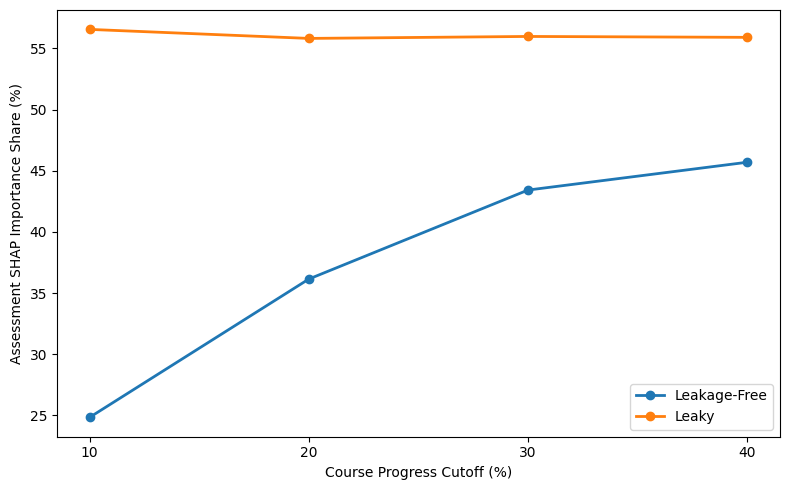

H2 assessment trajectory figure saved.


In [ ]:
import matplotlib.pyplot as plt

plot_h2 = assessment_trajectory.copy()

plot_h2["Cutoff_Number"] = (
    plot_h2["Cutoff"]
    .str.replace("%", "", regex=False)
    .astype(int)
)

plot_h2 = plot_h2.sort_values(
    "Cutoff_Number"
)

plt.figure(figsize=(8, 5))

plt.plot(
    plot_h2["Cutoff_Number"],
    plot_h2["LF_Share_Percent"],
    marker="o",
    linewidth=2,
    label="Leakage-Free"
)

plt.plot(
    plot_h2["Cutoff_Number"],
    plot_h2["Leaky_Share_Percent"],
    marker="o",
    linewidth=2,
    label="Leaky"
)

plt.xlabel("Course Progress Cutoff (%)")
plt.ylabel("Assessment SHAP Importance Share (%)")

plt.xticks(
    [10, 20, 30, 40]
)

plt.legend()

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_PATH,
        "Figure_H2_Assessment_SHAP_Trajectory.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("H2 assessment trajectory figure saved.")

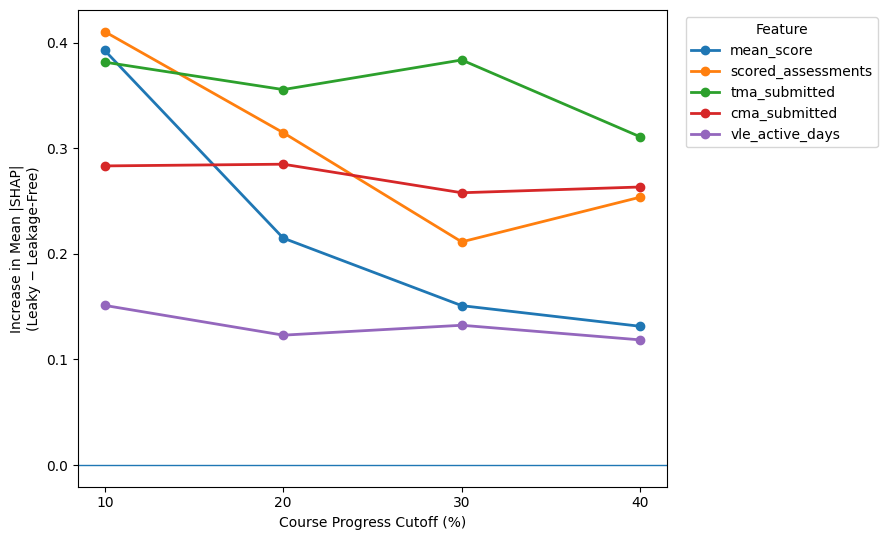

Individual-feature H2 figure saved.


In [ ]:
import matplotlib.pyplot as plt

selected_features = [
    "mean_score",
    "scored_assessments",
    "tma_submitted",
    "cma_submitted",
    "vle_active_days"
]

plot_features = (
    feature_shap_all[
        feature_shap_all[
            "Original_Feature"
        ].isin(selected_features)
    ]
    .copy()
)

plot_features["Cutoff_Number"] = (
    plot_features["Cutoff"]
    .str.replace("%", "", regex=False)
    .astype(int)
)

plot_features = plot_features.sort_values(
    [
        "Original_Feature",
        "Cutoff_Number"
    ]
)

plt.figure(figsize=(9, 5.5))

for feature in selected_features:

    temp = plot_features[
        plot_features[
            "Original_Feature"
        ] == feature
    ]

    plt.plot(
        temp["Cutoff_Number"],
        temp["SHAP_Change"],
        marker="o",
        linewidth=2,
        label=feature
    )

plt.axhline(
    y=0,
    linewidth=1
)

plt.xlabel(
    "Course Progress Cutoff (%)"
)

plt.ylabel(
    "Increase in Mean |SHAP|\n(Leaky − Leakage-Free)"
)

plt.xticks(
    [10, 20, 30, 40]
)

plt.legend(
    title="Feature",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_PATH,
        "Figure_H2_Individual_Feature_SHAP_Inflation.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    "Individual-feature H2 figure saved."
)

In [ ]:
final_h1_h2 = pd.DataFrame({
    "Cutoff": [
        "10%",
        "20%",
        "30%",
        "40%"
    ],

    "LF_Accuracy": [
        0.5359,
        0.5781,
        0.6172,
        0.6504
    ],

    "Leaky_Accuracy": [
        0.7055,
        0.7142,
        0.7217,
        0.7301
    ],

    "Accuracy_Inflation_PP": [
        16.96,
        13.61,
        10.46,
        7.98
    ],

    "LF_Assessment_SHAP_Share": [
        24.83,
        36.14,
        43.42,
        45.70
    ],

    "Leaky_Assessment_SHAP_Share": [
        56.56,
        55.82,
        55.98,
        55.91
    ],

    "Assessment_SHAP_Inflation_PP": [
        31.73,
        19.68,
        12.56,
        10.22
    ]
})

print(
    "=== FINAL H1 + H2 EVIDENCE TABLE ==="
)

print(
    final_h1_h2
    .round(2)
    .to_string(index=False)
)

final_h1_h2.to_csv(
    os.path.join(
        RESULTS_PATH,
        "final_H1_H2_evidence_table.csv"
    ),
    index=False
)

print(
    "\nFinal H1 + H2 evidence table saved."
)

=== FINAL H1 + H2 EVIDENCE TABLE ===
Cutoff  LF_Accuracy  Leaky_Accuracy  Accuracy_Inflation_PP  LF_Assessment_SHAP_Share  Leaky_Assessment_SHAP_Share  Assessment_SHAP_Inflation_PP
   10%         0.54            0.71                  16.96                     24.83                        56.56                         31.73
   20%         0.58            0.71                  13.61                     36.14                        55.82                         19.68
   30%         0.62            0.72                  10.46                     43.42                        55.98                         12.56
   40%         0.65            0.73                   7.98                     45.70                        55.91                         10.22

Final H1 + H2 evidence table saved.


In [ ]:
print("Class order:", class_order)

fail_idx = class_order.index("Fail")
withdrawn_idx = class_order.index("Withdrawn")

print("Fail class index:", fail_idx)
print("Withdrawn class index:", withdrawn_idx)

Class order: ['Distinction', 'Pass', 'Fail', 'Withdrawn']
Fail class index: 2
Withdrawn class index: 3


In [ ]:
def class_specific_shap_family(
    shap_lf,
    shap_leaky,
    class_index,
    class_name
):

    # --------------------------------
    # Mean absolute SHAP for one class
    # --------------------------------
    lf_importance = (
        np.abs(
            shap_lf[:, :, class_index]
        )
        .mean(axis=0)
    )

    leaky_importance = (
        np.abs(
            shap_leaky[:, :, class_index]
        )
        .mean(axis=0)
    )

    encoded = pd.DataFrame({
        "Transformed_Feature":
            feature_names_lf,

        "LF_MeanAbsSHAP":
            lf_importance,

        "Leaky_MeanAbsSHAP":
            leaky_importance
    })

    encoded["Original_Feature"] = (
        encoded["Transformed_Feature"]
        .apply(
            recover_original_feature
        )
    )

    # --------------------------------
    # Collapse one-hot columns
    # --------------------------------
    features = (
        encoded
        .groupby(
            "Original_Feature",
            as_index=False
        )[
            [
                "LF_MeanAbsSHAP",
                "Leaky_MeanAbsSHAP"
            ]
        ]
        .sum()
    )

    features["Feature_Family"] = (
        features[
            "Original_Feature"
        ].apply(
            assign_feature_family
        )
    )

    # --------------------------------
    # Family aggregation
    # --------------------------------
    family = (
        features
        .groupby(
            "Feature_Family",
            as_index=False
        )[
            [
                "LF_MeanAbsSHAP",
                "Leaky_MeanAbsSHAP"
            ]
        ]
        .sum()
    )

    family["LF_Share_Percent"] = (
        family["LF_MeanAbsSHAP"]
        /
        family["LF_MeanAbsSHAP"].sum()
        * 100
    )

    family["Leaky_Share_Percent"] = (
        family["Leaky_MeanAbsSHAP"]
        /
        family["Leaky_MeanAbsSHAP"].sum()
        * 100
    )

    family["Share_Change_PP"] = (
        family["Leaky_Share_Percent"]
        -
        family["LF_Share_Percent"]
    )

    family.insert(
        0,
        "Class",
        class_name
    )

    return features, family

In [ ]:
fail_features_10, fail_family_10 = (
    class_specific_shap_family(
        shap_lf_10,
        shap_leaky_10,
        fail_idx,
        "Fail"
    )
)

withdrawn_features_10, withdrawn_family_10 = (
    class_specific_shap_family(
        shap_lf_10,
        shap_leaky_10,
        withdrawn_idx,
        "Withdrawn"
    )
)

adverse_family_10 = pd.concat(
    [
        fail_family_10,
        withdrawn_family_10
    ],
    ignore_index=True
)

print(
    "=== 10% CLASS-SPECIFIC SHAP ROBUSTNESS ==="
)

print(
    adverse_family_10[
        [
            "Class",
            "Feature_Family",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .round(2)
    .sort_values(
        [
            "Class",
            "Leaky_Share_Percent"
        ],
        ascending=[
            True,
            False
        ]
    )
    .to_string(index=False)
)

=== 10% CLASS-SPECIFIC SHAP ROBUSTNESS ===
    Class    Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
     Fail        Assessment         15.030000            45.209999        30.170000
     Fail     In-course VLE         27.170000            27.700001         0.530000
     Fail Static/Background         50.799999            24.780001       -26.020000
     Fail    Pre-course VLE          7.000000             2.310000        -4.690000
Withdrawn        Assessment         27.020000            55.299999        28.280001
Withdrawn Static/Background         54.070000            20.790001       -33.279999
Withdrawn     In-course VLE         16.000000            20.120001         4.130000
Withdrawn    Pre-course VLE          2.910000             3.790000         0.880000


In [ ]:
adverse_family_10.to_csv(
    os.path.join(
        RESULTS_PATH,
        "shap_class_specific_fail_withdrawn_10pct.csv"
    ),
    index=False
)

print(
    "Fail/Withdrawn class-specific SHAP robustness saved."
)

Fail/Withdrawn class-specific SHAP robustness saved.


In [ ]:
print("=== 10% FAIL / WITHDRAWN SHAP ROBUSTNESS ===")

print(
    adverse_family_10[
        [
            "Class",
            "Feature_Family",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .round(2)
    .sort_values(
        ["Class", "Leaky_Share_Percent"],
        ascending=[True, False]
    )
    .to_string(index=False)
)

=== 10% FAIL / WITHDRAWN SHAP ROBUSTNESS ===
    Class    Feature_Family  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
     Fail        Assessment         15.030000            45.209999        30.170000
     Fail     In-course VLE         27.170000            27.700001         0.530000
     Fail Static/Background         50.799999            24.780001       -26.020000
     Fail    Pre-course VLE          7.000000             2.310000        -4.690000
Withdrawn        Assessment         27.020000            55.299999        28.280001
Withdrawn Static/Background         54.070000            20.790001       -33.279999
Withdrawn     In-course VLE         16.000000            20.120001         4.130000
Withdrawn    Pre-course VLE          2.910000             3.790000         0.880000


In [ ]:
adverse_assessment_summary = (
    adverse_family_10[
        adverse_family_10[
            "Feature_Family"
        ] == "Assessment"
    ][
        [
            "Class",
            "LF_Share_Percent",
            "Leaky_Share_Percent",
            "Share_Change_PP"
        ]
    ]
    .copy()
)

print("=== FINAL ADVERSE-CLASS H2 ROBUSTNESS ===")

print(
    adverse_assessment_summary
    .round(2)
    .to_string(index=False)
)

adverse_assessment_summary.to_csv(
    os.path.join(
        RESULTS_PATH,
        "final_H2_adverse_class_robustness.csv"
    ),
    index=False
)

print("\nFinal adverse-class robustness summary saved.")

=== FINAL ADVERSE-CLASS H2 ROBUSTNESS ===
    Class  LF_Share_Percent  Leaky_Share_Percent  Share_Change_PP
     Fail             15.03            45.209999        30.170000
Withdrawn             27.02            55.299999        28.280001

Final adverse-class robustness summary saved.
